In [128]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in data/raw:")
print(os.listdir("../data/raw"))

Current folder:
c:\Users\ASUS\OneDrive\Desktop\Loan_Default_Prediction\notebooks

Files in data/raw:
['application_train.csv']


In [129]:
import os

path = "../data/raw/application_train.csv"

print("Exists:", os.path.exists(path))
print("Is file:", os.path.isfile(path))
print("Is folder:", os.path.isdir(path))

Exists: True
Is file: True
Is folder: False


In [130]:
import os

print(os.listdir("../data/raw/application_train.csv"))

NotADirectoryError: [WinError 267] The directory name is invalid: '../data/raw/application_train.csv'

In [ ]:
import os

path = "../data/raw/application_train.csv"

print("Exists:", os.path.exists(path))
print("Is file:", os.path.isfile(path))
print("Is folder:", os.path.isdir(path))

Exists: True
Is file: True
Is folder: False


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/application_train.csv")

df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
df.shape

(307511, 122)

In [ ]:
df.columns.tolist()

['SK_ID_CURR',
 'TARGET',
 'NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'OWN_CAR_AGE',
 'FLAG_MOBIL',
 'FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_CONT_MOBILE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'OCCUPATION_TYPE',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'WEEKDAY_APPR_PROCESS_START',
 'HOUR_APPR_PROCESS_START',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'ORGANIZATION_TYPE',
 'EXT_SOURCE_1',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'APARTMENTS_AVG',
 'BASEMENTAREA_AVG',
 'YEARS_BEGINEXPLUATATION_A

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 286.2 MB


In [ ]:
df.isnull().sum().sort_values(ascending=False).head(20)

COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
COMMONAREA_MEDI             214865
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
FLOORSMIN_MEDI              208642
YEARS_BUILD_AVG             204488
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
OWN_CAR_AGE                 202929
LANDAREA_MEDI               182590
LANDAREA_AVG                182590
LANDAREA_MODE               182590
dtype: int64

In [ ]:
df["TARGET"].value_counts()

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [ ]:
df["TARGET"].value_counts(normalize=True) * 100

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64

In [ ]:
X = df.drop("TARGET", axis=1)
y = df["TARGET"]

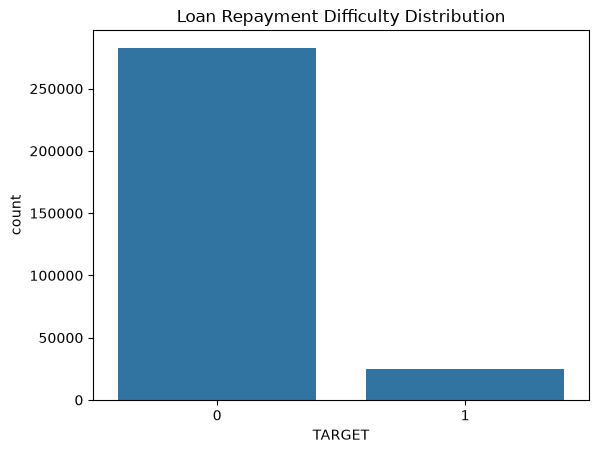

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x=df["TARGET"])
plt.title("Loan Repayment Difficulty Distribution")
plt.show()

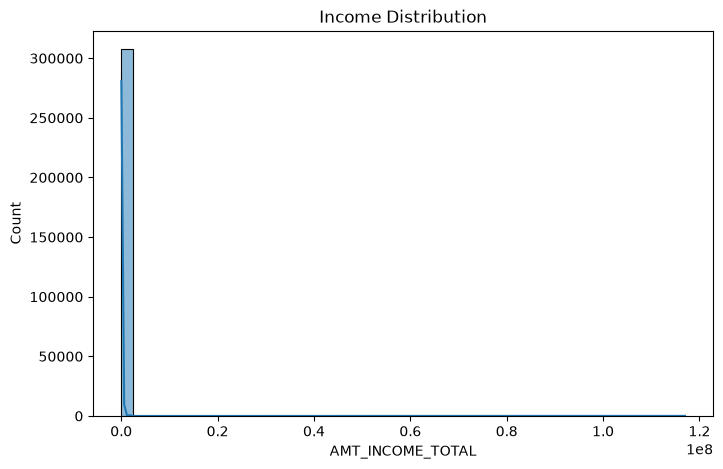

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["AMT_INCOME_TOTAL"],
    bins=50,
    kde=True
)

plt.title("Income Distribution")
plt.show()

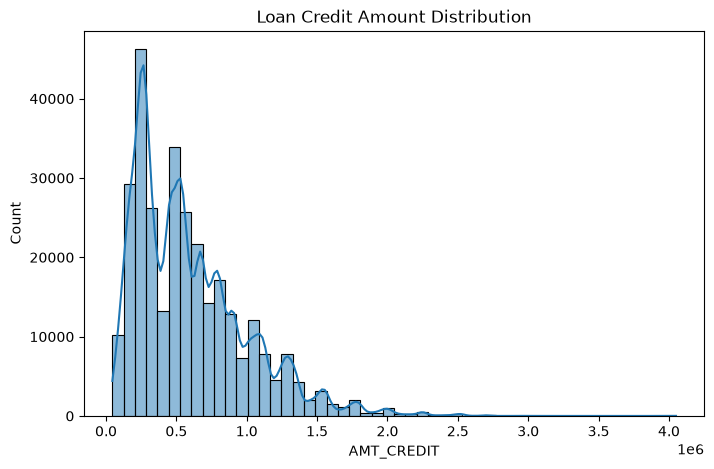

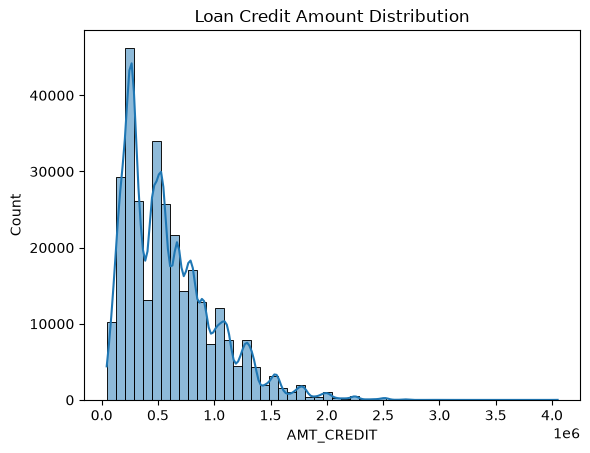

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["AMT_CREDIT"],
    bins=50,
    kde=True
)

plt.title("Loan Credit Amount Distribution")
plt.show()

sns.histplot(
    df["AMT_CREDIT"],
    bins=50,
    kde=True
)

plt.title("Loan Credit Amount Distribution")
plt.show()

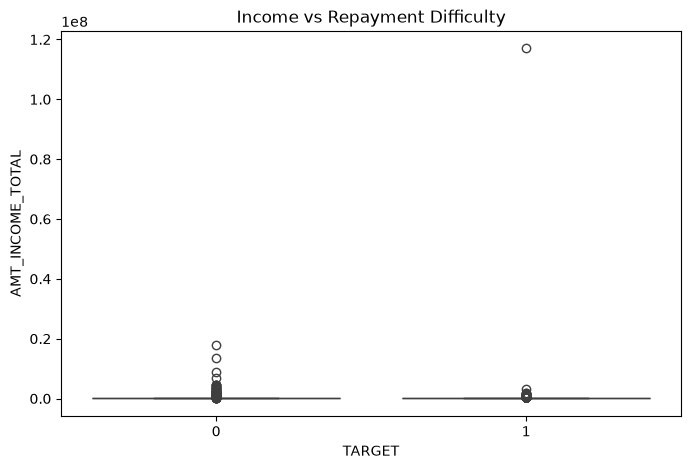

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="TARGET",
    y="AMT_INCOME_TOTAL",
    data=df
)

plt.title("Income vs Repayment Difficulty")
plt.show()

In [ ]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

missing.head(30)

COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MEDI              208642
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
BASEMENTAREA_MODE           179943
BASEMENTAREA_MEDI           179943
BASEMENTAREA_AVG            179943
EXT_SOURCE_1                173378
NONLIVINGAREA_MEDI          169682
NONLIVINGAREA_AVG           169682
NONLIVINGAREA_MODE          169682
ELEVATORS_MEDI              163891
ELEVATORS_MODE      

In [ ]:
X = df.drop(
    ["TARGET", "SK_ID_CURR"],
    axis=1
)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns

print("Numerical columns:", len(numeric_features))
print("Categorical columns:", len(categorical_features))

Numerical columns: 104
Categorical columns: 16


C:\Users\ASUS\AppData\Local\Temp\ipykernel_21092\3911713311.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [ ]:
print("\nCategorical columns:")
print(categorical_features.tolist())


Categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [ ]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

In [ ]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ]
)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]
)

In [ ]:
logistic_model.fit(X_train, y_train)

c:\Users\ASUS\OneDrive\Desktop\Loan_Default_Prediction\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](120,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_MON','AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,120
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dr

In [ ]:
y_pred = logistic_model.predict(X_test)

In [ ]:
y_probability = logistic_model.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [ ]:
print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred))

print("Recall:",
      recall_score(y_test, y_pred))

print("F1 Score:",
      f1_score(y_test, y_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, y_probability))

Accuracy: 0.6032063476578379
Precision: 0.11462669997224535
Recall: 0.5822759315206445
F1 Score: 0.19154574968528457
ROC-AUC: 0.6238273738804195


In [ ]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.94      0.61      0.74     56538
           1       0.11      0.58      0.19      4965

    accuracy                           0.60     61503
   macro avg       0.53      0.59      0.46     61503
weighted avg       0.88      0.60      0.69     61503



In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[34208 22330]
 [ 2074  2891]]


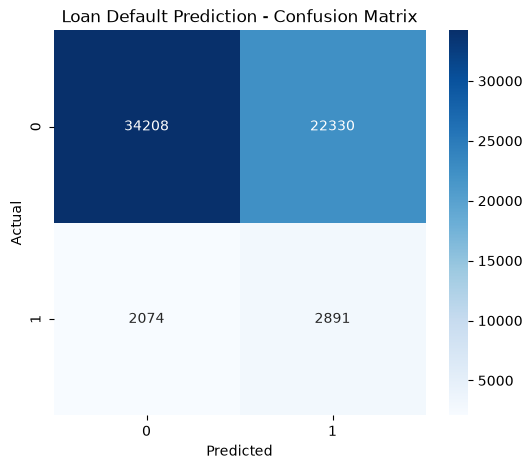

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Loan Default Prediction - Confusion Matrix")

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        ))
    ]
)

In [ ]:
random_forest_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](120,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_MON','AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,120
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dr

In [ ]:
rf_pred = random_forest_model.predict(X_test)

rf_probability = random_forest_model.predict_proba(
    X_test
)[:, 1]

In [ ]:
print(
    classification_report(
        y_test,
        rf_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        rf_probability
    )
)

              precision    recall  f1-score   support

           0       0.92      0.99      0.96     56538
           1       0.40      0.05      0.08      4965

    accuracy                           0.92     61503
   macro avg       0.66      0.52      0.52     61503
weighted avg       0.88      0.92      0.89     61503

ROC-AUC: 0.7404064790154236


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "ROC-AUC": [
        roc_auc_score(
            y_test,
            y_probability
        ),
        roc_auc_score(
            y_test,
            rf_probability
        )
    ],
    "F1 Score": [
        f1_score(
            y_test,
            y_pred
        ),
        f1_score(
            y_test,
            rf_pred
        )
    ],
    "Recall": [
        recall_score(
            y_test,
            y_pred
        ),
        recall_score(
            y_test,
            rf_pred
        )
    ]
})

results

,Model,ROC-AUC,F1 Score,Recall
0,Logistic Regression,0.623827,0.191546,0.582276
1,Random Forest,0.740406,0.082761,0.046123


In [ ]:
df_fe = df.copy()

In [ ]:
important_columns = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

print(df_fe[important_columns].head())

   AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE  DAYS_BIRTH  \
0          202500.0    406597.5      24700.5         351000.0       -9461   
1          270000.0   1293502.5      35698.5        1129500.0      -16765   
2           67500.0    135000.0       6750.0         135000.0      -19046   
3          135000.0    312682.5      29686.5         297000.0      -19005   
4          121500.0    513000.0      21865.5         513000.0      -19932   

   DAYS_EMPLOYED  
0           -637  
1          -1188  
2           -225  
3          -3039  
4          -3038  


In [ ]:
df_fe["CREDIT_INCOME_RATIO"] = (
    df_fe["AMT_CREDIT"] /
    (df_fe["AMT_INCOME_TOTAL"] + 1)
)

In [ ]:
df_fe["ANNUITY_INCOME_RATIO"] = (
    df_fe["AMT_ANNUITY"] /
    (df_fe["AMT_INCOME_TOTAL"] + 1)
)

In [ ]:
df_fe["CREDIT_GOODS_RATIO"] = (
    df_fe["AMT_CREDIT"] /
    (df_fe["AMT_GOODS_PRICE"] + 1)
)

In [ ]:
df_fe["AGE_YEARS"] = (
    -df_fe["DAYS_BIRTH"] / 365
)

In [ ]:
print(df_fe["AGE_YEARS"].describe())

count    307511.000000
mean         43.936973
std          11.956133
min          20.517808
25%          34.008219
50%          43.150685
75%          53.923288
max          69.120548
Name: AGE_YEARS, dtype: float64


In [ ]:
df_fe["EMPLOYED_YEARS"] = (
    -df_fe["DAYS_EMPLOYED"] / 365
)

In [ ]:
print(df_fe["EMPLOYED_YEARS"].describe())

count    307511.000000
mean       -174.835742
std         387.056895
min       -1000.665753
25%           0.791781
50%           3.323288
75%           7.561644
max          49.073973
Name: EMPLOYED_YEARS, dtype: float64


In [ ]:
new_features = [
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "CREDIT_GOODS_RATIO",
    "AGE_YEARS",
    "EMPLOYED_YEARS"
]

print(df_fe[new_features].describe())

       CREDIT_INCOME_RATIO  ANNUITY_INCOME_RATIO  CREDIT_GOODS_RATIO  \
count        307511.000000         307499.000000       307233.000000   
mean              3.957537              0.180928            1.122992   
std               2.689696              0.094573            0.124044   
min               0.004808              0.000224            0.150000   
25%               2.018659              0.114781            0.999999   
50%               3.265042              0.162832            1.118798   
75%               5.159857              0.229064            1.197998   
max              84.733539              1.875892            5.999867   

           AGE_YEARS  EMPLOYED_YEARS  
count  307511.000000   307511.000000  
mean       43.936973     -174.835742  
std        11.956133      387.056895  
min        20.517808    -1000.665753  
25%        34.008219        0.791781  
50%        43.150685        3.323288  
75%        53.923288        7.561644  
max        69.120548       49.073973  


In [ ]:
print(df_fe[new_features].head(10))

   CREDIT_INCOME_RATIO  ANNUITY_INCOME_RATIO  CREDIT_GOODS_RATIO  AGE_YEARS  \
0             2.007879              0.121977            1.158394  25.920548   
1             4.790732              0.132216            1.145198  45.931507   
2             1.999970              0.099999            0.999993  52.180822   
3             2.316150              0.219898            1.052799  52.068493   
4             4.222187              0.179961            0.999998  54.608219   
5             4.954450              0.277952            1.079196  46.413699   
6             9.126999              0.241525            1.118799  37.747945   
7             4.249988              0.116875            0.999999  51.643836   
8             9.063119              0.300677            1.116156  55.065753   
9             2.999978              0.149999            0.999998  39.641096   

   EMPLOYED_YEARS  
0        1.745205  
1        3.254795  
2        0.616438  
3        8.326027  
4        8.323288  
5        4

In [ ]:
X_fe = df_fe.drop(
    ["TARGET", "SK_ID_CURR"],
    axis=1
)

y_fe = df_fe["TARGET"]

In [ ]:
print("X shape:", X_fe.shape)
print("y shape:", y_fe.shape)

X shape: (307511, 125)
y shape: (307511,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe,
    y_fe,
    test_size=0.2,
    random_state=42,
    stratify=y_fe
)

In [ ]:
print("Training:", X_train_fe.shape)
print("Testing:", X_test_fe.shape)

Training: (246008, 125)
Testing: (61503, 125)


In [ ]:
numeric_features_fe = X_train_fe.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features_fe = X_train_fe.select_dtypes(
    include=["object"]
).columns

print("Numerical features:", len(numeric_features_fe))
print("Categorical features:", len(categorical_features_fe))

Numerical features: 109
Categorical features: 16


C:\Users\ASUS\AppData\Local\Temp\ipykernel_21092\1117383247.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features_fe = X_train_fe.select_dtypes(


In [ ]:
numeric_transformer_fe = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer_fe = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [ ]:
preprocessor_fe = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_fe, numeric_features_fe),
        ("cat", categorical_transformer_fe, categorical_features_fe)
    ]
)

In [ ]:
logistic_fe = Pipeline(
    steps=[
        ("preprocessor", preprocessor_fe),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]
)

In [ ]:
logistic_fe.fit(
    X_train_fe,
    y_train_fe
)

c:\Users\ASUS\OneDrive\Desktop\Loan_Default_Prediction\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](125,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'CREDIT_GOODS_RATIO','AGE_YEARS','EMPLOYED_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,125
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By sp

In [ ]:
logistic_fe_pred = logistic_fe.predict(X_test_fe)

logistic_fe_probability = (
    logistic_fe.predict_proba(X_test_fe)[:, 1]
)

In [ ]:
print(
    classification_report(
        y_test_fe,
        logistic_fe_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test_fe,
        logistic_fe_probability
    )
)

              precision    recall  f1-score   support

           0       0.94      0.61      0.74     56538
           1       0.11      0.58      0.19      4965

    accuracy                           0.60     61503
   macro avg       0.53      0.59      0.46     61503
weighted avg       0.88      0.60      0.69     61503

ROC-AUC: 0.62481967497054


In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Feature Engineered Logistic Regression"
    ],
    
    "ROC-AUC": [
        roc_auc_score(y_test, y_probability),
        roc_auc_score(y_test_fe, logistic_fe_probability)
    ],
    
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test_fe, logistic_fe_pred)
    ],
    
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test_fe, logistic_fe_pred)
    ]
})

comparison

,Model,ROC-AUC,F1 Score,Recall
0,Original Logistic Regression,0.623827,0.191546,0.582276
1,Feature Engineered Logistic Regression,0.624820,0.192010,0.583686


In [ ]:
comparison
print(classification_report(y_test_fe, logistic_fe_pred))

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test_fe,
        logistic_fe_probability
    )
)

              precision    recall  f1-score   support

           0       0.94      0.61      0.74     56538
           1       0.11      0.58      0.19      4965

    accuracy                           0.60     61503
   macro avg       0.53      0.59      0.46     61503
weighted avg       0.88      0.60      0.69     61503

ROC-AUC: 0.62481967497054


In [ ]:
from sklearn.ensemble import RandomForestClassifier

random_forest_fe = Pipeline(
    steps=[
        ("preprocessor", preprocessor_fe),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
            class_weight="balanced",
            max_depth=12,
            min_samples_leaf=10
        ))
    ]
)

In [ ]:
random_forest_fe.fit(
    X_train_fe,
    y_train_fe
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](125,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'CREDIT_GOODS_RATIO','AGE_YEARS','EMPLOYED_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,125
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By sp

In [ ]:
rf_fe_pred = random_forest_fe.predict(X_test_fe)

rf_fe_probability = (
    random_forest_fe.predict_proba(X_test_fe)[:, 1]
)

In [ ]:
print(
    classification_report(
        y_test_fe,
        rf_fe_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test_fe,
        rf_fe_probability
    )
)

              precision    recall  f1-score   support

           0       0.96      0.73      0.83     56538
           1       0.17      0.61      0.26      4965

    accuracy                           0.72     61503
   macro avg       0.56      0.67      0.54     61503
weighted avg       0.89      0.72      0.78     61503

ROC-AUC: 0.7378950078830137


In [ ]:
from sklearn.metrics import average_precision_score

In [ ]:
print(
    "PR-AUC:",
    average_precision_score(
        y_test_fe,
        rf_fe_probability
    )
)

PR-AUC: 0.2191449474638141


In [ ]:
print(
    "Logistic Regression PR-AUC:",
    average_precision_score(
        y_test_fe,
        logistic_fe_probability
    )
)

Logistic Regression PR-AUC: 0.11883050360272883


In [ ]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],

    "ROC-AUC": [
        roc_auc_score(
            y_test_fe,
            logistic_fe_probability
        ),
        roc_auc_score(
            y_test_fe,
            rf_fe_probability
        )
    ],

    "PR-AUC": [
        average_precision_score(
            y_test_fe,
            logistic_fe_probability
        ),
        average_precision_score(
            y_test_fe,
            rf_fe_probability
        )
    ],

    "F1": [
        f1_score(
            y_test_fe,
            logistic_fe_pred
        ),
        f1_score(
            y_test_fe,
            rf_fe_pred
        )
    ],

    "Recall": [
        recall_score(
            y_test_fe,
            logistic_fe_pred
        ),
        recall_score(
            y_test_fe,
            rf_fe_pred
        )
    ],

    "Precision": [
        precision_score(
            y_test_fe,
            logistic_fe_pred
        ),
        precision_score(
            y_test_fe,
            rf_fe_pred
        )
    ]
})

model_results

,Model,ROC-AUC,PR-AUC,F1,Recall,Precision
0,Logistic Regression,0.624820,0.118831,0.192010,0.583686,0.114904
1,Random Forest,0.737895,0.219145,0.261072,0.608459,0.166190


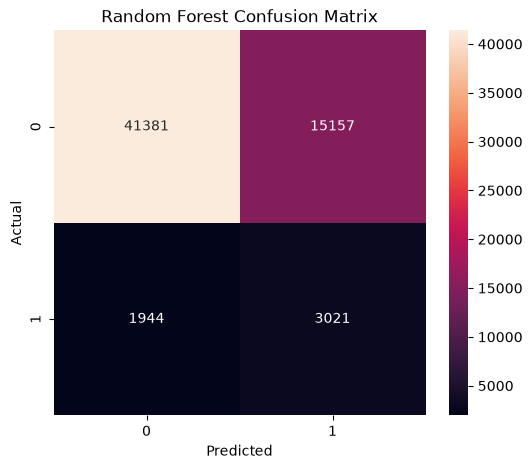

In [ ]:
rf_cm = confusion_matrix(
    y_test_fe,
    rf_fe_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [ ]:
print(
    classification_report(
        y_test_fe,
        rf_fe_pred
    )
)

              precision    recall  f1-score   support

           0       0.96      0.73      0.83     56538
           1       0.17      0.61      0.26      4965

    accuracy                           0.72     61503
   macro avg       0.56      0.67      0.54     61503
weighted avg       0.89      0.72      0.78     61503



In [ ]:
print(
    "ROC-AUC:",
    roc_auc_score(
        y_test_fe,
        rf_fe_probability
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test_fe,
        rf_fe_probability
    )
)

ROC-AUC: 0.7378950078830137
PR-AUC: 0.2191449474638141


In [ ]:
model_results

,Model,ROC-AUC,PR-AUC,F1,Recall,Precision
0,Logistic Regression,0.624820,0.118831,0.192010,0.583686,0.114904
1,Random Forest,0.737895,0.219145,0.261072,0.608459,0.166190


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

In [ ]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 452.2 kB/s eta 0:01:48
   ---------------------------------------- 0.5/48.9 MB 452.2 kB/s eta 0:01:48
    --------------------------------------- 0.8/48.9 MB 549.4 kB/s eta 0:01:28
    --------------------------------------- 0.8/48.9 MB 549.4 kB/s eta 0:01:28
    --------------------------------------- 1.0/48.9 MB 600.5 kB/s eta 0:01:20
   - -------------------------------------- 1.3/48.9 MB 619.7 kB/s eta 0:01:17
   - -------------------------------


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import xgboost

print(xgboost.__version__)

3.4.1


In [ ]:
from xgboost import XGBClassifier

In [ ]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score,
    f1_score,
    recall_score,
    precision_score
)

from xgboost import XGBClassifier

In [ ]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/application_train.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (307511, 122)
   SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR  \
0      100002       1         Cash loans           M            N   
1      100003       0         Cash loans           F            N   
2      100004       0    Revolving loans           M            Y   
3      100006       0         Cash loans           F            N   
4      100007       0         Cash loans           M            N   

  FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
0               Y             0          202500.0    406597.5      24700.5   
1               N             0          270000.0   1293502.5      35698.5   
2               Y             0           67500.0    135000.0       6750.0   
3               Y             0          135000.0    312682.5      29686.5   
4               Y             0          121500.0    513000.0      21865.5   

   ...  FLAG_DOCUMENT_18 FLAG_DOCUMENT_19 FLAG_DOCUMENT_20 FLAG_DOCUMENT_21  \
0  ...  

In [ ]:
print("TARGET column exists:", "TARGET" in df.columns)
print(df["TARGET"].value_counts())

TARGET column exists: True
TARGET
0    282686
1     24825
Name: count, dtype: int64


In [ ]:
df_fe = df.copy()

df_fe["CREDIT_INCOME_RATIO"] = (
    df_fe["AMT_CREDIT"] /
    (df_fe["AMT_INCOME_TOTAL"] + 1)
)

df_fe["ANNUITY_INCOME_RATIO"] = (
    df_fe["AMT_ANNUITY"] /
    (df_fe["AMT_INCOME_TOTAL"] + 1)
)

df_fe["CREDIT_GOODS_RATIO"] = (
    df_fe["AMT_CREDIT"] /
    (df_fe["AMT_GOODS_PRICE"] + 1)
)

df_fe["AGE_YEARS"] = (
    -df_fe["DAYS_BIRTH"] / 365
)

df_fe["EMPLOYED_YEARS"] = (
    -df_fe["DAYS_EMPLOYED"] / 365
)

print("Feature-engineered dataset:", df_fe.shape)

Feature-engineered dataset: (307511, 127)


In [ ]:
X_fe = df_fe.drop(
    ["TARGET", "SK_ID_CURR"],
    axis=1
)

y_fe = df_fe["TARGET"]

print("X:", X_fe.shape)
print("y:", y_fe.shape)

X: (307511, 125)
y: (307511,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe,
    y_fe,
    test_size=0.2,
    random_state=42,
    stratify=y_fe
)

print("Training:", X_train_fe.shape)
print("Testing:", X_test_fe.shape)

Training: (246008, 125)
Testing: (61503, 125)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features_fe = X_train_fe.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features_fe = X_train_fe.select_dtypes(
    include=["object"]
).columns

print("Numerical features:", len(numeric_features_fe))
print("Categorical features:", len(categorical_features_fe))

Numerical features: 109
Categorical features: 16


C:\Users\ASUS\AppData\Local\Temp\ipykernel_18412\441725745.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features_fe = X_train_fe.select_dtypes(


In [ ]:
numeric_transformer_fe = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer_fe = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [ ]:
preprocessor_fe = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_fe, numeric_features_fe),
        ("cat", categorical_transformer_fe, categorical_features_fe)
    ]
)

In [ ]:
print("df:", df.shape)
print("df_fe:", df_fe.shape)
print("X_train_fe:", X_train_fe.shape)
print("X_test_fe:", X_test_fe.shape)
print("preprocessor_fe:", type(preprocessor_fe))

df: (307511, 122)
df_fe: (307511, 127)
X_train_fe: (246008, 125)
X_test_fe: (61503, 125)
preprocessor_fe: <class 'sklearn.compose._column_transformer.ColumnTransformer'>


In [ ]:
from xgboost import XGBClassifier

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_fe),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            n_jobs=-1,
            eval_metric="logloss"
        ))
    ]
)

In [ ]:
xgb_model.fit(
    X_train_fe,
    y_train_fe
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](125,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'CREDIT_GOODS_RATIO','AGE_YEARS','EMPLOYED_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,125
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By sp

In [ ]:
xgb_pred = xgb_model.predict(X_test_fe)

xgb_probability = xgb_model.predict_proba(
    X_test_fe
)[:, 1]

In [ ]:
print(
    classification_report(
        y_test_fe,
        xgb_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test_fe,
        xgb_probability
    )
)

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.58      0.02      0.05      4965

    accuracy                           0.92     61503
   macro avg       0.75      0.51      0.50     61503
weighted avg       0.89      0.92      0.88     61503

ROC-AUC: 0.7627540916879082


In [ ]:
from sklearn.metrics import average_precision_score

xgb_pr_auc = average_precision_score(
    y_test_fe,
    xgb_probability
)

print("PR-AUC:", xgb_pr_auc)

PR-AUC: 0.2538700667994463


In [ ]:
print(type(xgb_pred))
print(type(xgb_probability))

print("XGBoost predictions:", len(xgb_pred))
print("XGBoost probabilities:", len(xgb_probability))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
XGBoost predictions: 61503
XGBoost probabilities: 61503


In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_fe = Pipeline(
    steps=[
        ("preprocessor", preprocessor_fe),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]
)

In [ ]:
logistic_fe.fit(
    X_train_fe,
    y_train_fe
)

c:\Users\ASUS\OneDrive\Desktop\Loan_Default_Prediction\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](125,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'CREDIT_GOODS_RATIO','AGE_YEARS','EMPLOYED_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,125
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By sp

In [ ]:
logistic_fe_pred = logistic_fe.predict(
    X_test_fe
)

logistic_fe_probability = logistic_fe.predict_proba(
    X_test_fe
)[:, 1]

In [ ]:
print("Logistic predictions:", len(logistic_fe_pred))
print("Logistic probabilities:", len(logistic_fe_probability))

Logistic predictions: 61503
Logistic probabilities: 61503


In [ ]:
print(
    classification_report(
        y_test_fe,
        xgb_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test_fe,
        xgb_probability
    )
)

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.58      0.02      0.05      4965

    accuracy                           0.92     61503
   macro avg       0.75      0.51      0.50     61503
weighted avg       0.89      0.92      0.88     61503

ROC-AUC: 0.7627540916879082


In [ ]:
print(
    "PR-AUC:",
    average_precision_score(
        y_test_fe,
        xgb_probability
    )
)

PR-AUC: 0.2538700667994463


In [ ]:
from sklearn.ensemble import RandomForestClassifier

random_forest_fe = Pipeline(
    steps=[
        ("preprocessor", preprocessor_fe),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
            class_weight="balanced",
            max_depth=12,
            min_samples_leaf=10
        ))
    ]
)

In [ ]:
random_forest_fe.fit(
    X_train_fe,
    y_train_fe
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](125,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'CREDIT_GOODS_RATIO','AGE_YEARS','EMPLOYED_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,125
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By sp

In [ ]:
rf_fe_pred = random_forest_fe.predict(
    X_test_fe
)

rf_fe_probability = random_forest_fe.predict_proba(
    X_test_fe
)[:, 1]

In [ ]:
print("Logistic:")
print(len(logistic_fe_pred))
print(len(logistic_fe_probability))

print("\nRandom Forest:")
print(len(rf_fe_pred))
print(len(rf_fe_probability))

print("\nXGBoost:")
print(len(xgb_pred))
print(len(xgb_probability))

Logistic:
61503
61503

Random Forest:
61503
61503

XGBoost:
61503
61503


In [ ]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],

    "ROC-AUC": [
        roc_auc_score(
            y_test_fe,
            logistic_fe_probability
        ),
        roc_auc_score(
            y_test_fe,
            rf_fe_probability
        ),
        roc_auc_score(
            y_test_fe,
            xgb_probability
        )
    ],

    "PR-AUC": [
        average_precision_score(
            y_test_fe,
            logistic_fe_probability
        ),
        average_precision_score(
            y_test_fe,
            rf_fe_probability
        ),
        average_precision_score(
            y_test_fe,
            xgb_probability
        )
    ],

    "F1": [
        f1_score(y_test_fe, logistic_fe_pred),
        f1_score(y_test_fe, rf_fe_pred),
        f1_score(y_test_fe, xgb_pred)
    ],

    "Recall": [
        recall_score(y_test_fe, logistic_fe_pred),
        recall_score(y_test_fe, rf_fe_pred),
        recall_score(y_test_fe, xgb_pred)
    ],

    "Precision": [
        precision_score(y_test_fe, logistic_fe_pred),
        precision_score(y_test_fe, rf_fe_pred),
        precision_score(y_test_fe, xgb_pred)
    ]
})

final_comparison

,Model,ROC-AUC,PR-AUC,F1,Recall,Precision
0,Logistic Regression,0.624820,0.118831,0.192010,0.583686,0.114904
1,Random Forest,0.737895,0.219145,0.261072,0.608459,0.166190
2,XGBoost,0.762754,0.253870,0.045666,0.023766,0.581281


In [ ]:
final_comparison

,Model,ROC-AUC,PR-AUC,F1,Recall,Precision
0,Logistic Regression,0.624820,0.118831,0.192010,0.583686,0.114904
1,Random Forest,0.737895,0.219145,0.261072,0.608459,0.166190
2,XGBoost,0.762754,0.253870,0.045666,0.023766,0.581281


In [ ]:
print(y_fe.value_counts())

TARGET
0    282686
1     24825
Name: count, dtype: int64


In [ ]:
print(
    y_fe.value_counts(normalize=True) * 100
)

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


In [ ]:
positive_rate = y_test_fe.mean()

print("Positive class rate:", positive_rate)

Positive class rate: 0.08072776937710356


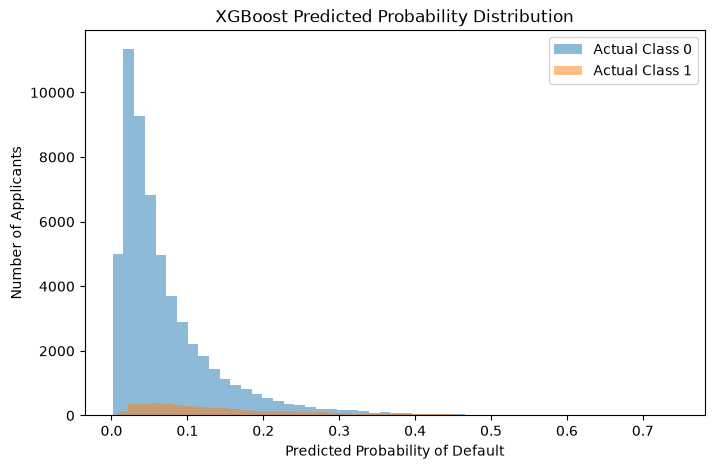

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    xgb_probability[y_test_fe.values == 0],
    bins=50,
    alpha=0.5,
    label="Actual Class 0"
)

plt.hist(
    xgb_probability[y_test_fe.values == 1],
    bins=50,
    alpha=0.5,
    label="Actual Class 1"
)

plt.xlabel("Predicted Probability of Default")
plt.ylabel("Number of Applicants")
plt.title("XGBoost Predicted Probability Distribution")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

thresholds = [
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70
]

for threshold in thresholds:

    threshold_pred = (
        xgb_probability >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_fe,
            threshold_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_fe,
            threshold_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_test_fe,
            threshold_pred,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Precision,Recall,F1
0,0.10,0.190709,0.596173,0.288978
1,0.15,0.247604,0.421551,0.311969
2,0.20,0.300041,0.295871,0.297941
3,0.25,0.353857,0.210675,0.264108
4,0.30,0.390122,0.141591,0.207773
5,0.35,0.442922,0.097684,0.160066
6,0.40,0.500782,0.064451,0.114204
7,0.45,0.547684,0.040483,0.075394
8,0.50,0.581281,0.023766,0.045666
9,0.55,0.625000,0.014099,0.027575


In [ ]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print(best_threshold_row)

Threshold    0.150000
Precision    0.247604
Recall       0.421551
F1           0.311969
Name: 1, dtype: float64


In [ ]:
best_threshold = best_threshold_row["Threshold"]

final_xgb_pred = (
    xgb_probability >= best_threshold
).astype(int)

print("Selected threshold:", best_threshold)

Selected threshold: 0.15


In [ ]:
print(
    classification_report(
        y_test_fe,
        final_xgb_pred
    )
)

              precision    recall  f1-score   support

           0       0.95      0.89      0.92     56538
           1       0.25      0.42      0.31      4965

    accuracy                           0.85     61503
   macro avg       0.60      0.65      0.61     61503
weighted avg       0.89      0.85      0.87     61503



In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test_fe,
    final_xgb_pred
)

print(cm)

[[50178  6360]
 [ 2872  2093]]


In [ ]:
threshold_df

,Threshold,Precision,Recall,F1
0,0.10,0.190709,0.596173,0.288978
1,0.15,0.247604,0.421551,0.311969
2,0.20,0.300041,0.295871,0.297941
3,0.25,0.353857,0.210675,0.264108
4,0.30,0.390122,0.141591,0.207773
5,0.35,0.442922,0.097684,0.160066
6,0.40,0.500782,0.064451,0.114204
7,0.45,0.547684,0.040483,0.075394
8,0.50,0.581281,0.023766,0.045666
9,0.55,0.625000,0.014099,0.027575


In [ ]:
print("Selected threshold:", best_threshold)

print(
    classification_report(
        y_test_fe,
        final_xgb_pred
    )
)

Selected threshold: 0.15
              precision    recall  f1-score   support

           0       0.95      0.89      0.92     56538
           1       0.25      0.42      0.31      4965

    accuracy                           0.85     61503
   macro avg       0.60      0.65      0.61     61503
weighted avg       0.89      0.85      0.87     61503



In [ ]:
print("Final ROC-AUC:", roc_auc_score(
    y_test_fe,
    xgb_probability
))

print("Final PR-AUC:", average_precision_score(
    y_test_fe,
    xgb_probability
))

Final ROC-AUC: 0.7627540916879082
Final PR-AUC: 0.2538700667994463


In [ ]:
print("Selected threshold:", best_threshold)

print("\nThreshold Results:")
display(threshold_df)

print("\nFinal Classification Report:")
print(classification_report(y_test_fe, final_xgb_pred))

print("\nFinal ROC-AUC:", roc_auc_score(y_test_fe, xgb_probability))
print("Final PR-AUC:", average_precision_score(y_test_fe, xgb_probability))

print("\nModel Comparison:")
display(final_comparison)

Selected threshold: 0.15

Threshold Results:


,Threshold,Precision,Recall,F1
0,0.10,0.190709,0.596173,0.288978
1,0.15,0.247604,0.421551,0.311969
2,0.20,0.300041,0.295871,0.297941
3,0.25,0.353857,0.210675,0.264108
4,0.30,0.390122,0.141591,0.207773
5,0.35,0.442922,0.097684,0.160066
6,0.40,0.500782,0.064451,0.114204
7,0.45,0.547684,0.040483,0.075394
8,0.50,0.581281,0.023766,0.045666
9,0.55,0.625000,0.014099,0.027575



Final Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.89      0.92     56538
           1       0.25      0.42      0.31      4965

    accuracy                           0.85     61503
   macro avg       0.60      0.65      0.61     61503
weighted avg       0.89      0.85      0.87     61503


Final ROC-AUC: 0.7627540916879082
Final PR-AUC: 0.2538700667994463

Model Comparison:


,Model,ROC-AUC,PR-AUC,F1,Recall,Precision
0,Logistic Regression,0.624820,0.118831,0.192010,0.583686,0.114904
1,Random Forest,0.737895,0.219145,0.261072,0.608459,0.166190
2,XGBoost,0.762754,0.253870,0.045666,0.023766,0.581281


In [ ]:
print("Selected threshold:", best_threshold)

print("\nThreshold Performance:")
display(threshold_df)

print("\nXGBoost Classification Report:")
print(classification_report(y_test_fe, final_xgb_pred))

print("\nXGBoost Confusion Matrix:")
print(confusion_matrix(y_test_fe, final_xgb_pred))

Selected threshold: 0.15

Threshold Performance:


,Threshold,Precision,Recall,F1
0,0.10,0.190709,0.596173,0.288978
1,0.15,0.247604,0.421551,0.311969
2,0.20,0.300041,0.295871,0.297941
3,0.25,0.353857,0.210675,0.264108
4,0.30,0.390122,0.141591,0.207773
5,0.35,0.442922,0.097684,0.160066
6,0.40,0.500782,0.064451,0.114204
7,0.45,0.547684,0.040483,0.075394
8,0.50,0.581281,0.023766,0.045666
9,0.55,0.625000,0.014099,0.027575



XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.89      0.92     56538
           1       0.25      0.42      0.31      4965

    accuracy                           0.85     61503
   macro avg       0.60      0.65      0.61     61503
weighted avg       0.89      0.85      0.87     61503


XGBoost Confusion Matrix:
[[50178  6360]
 [ 2872  2093]]


In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from xgboost import XGBClassifier

In [ ]:
scale_pos_weight = (
    y_train_fe.value_counts()[0] /
    y_train_fe.value_counts()[1]
)

print("Scale Pos Weight:", scale_pos_weight)

Scale Pos Weight: 11.38710976837865


In [ ]:
xgb_tuning = Pipeline([
    ("preprocessor", preprocessor_fe),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
param_distributions = {
    "classifier__n_estimators": [200, 300, 400],
    "classifier__max_depth": [3, 5, 6, 8],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__min_child_weight": [1, 5, 10],
    "classifier__subsample": [0.7, 0.8, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 1.0],
    "classifier__gamma": [0, 0.1, 0.3],
    "classifier__reg_alpha": [0, 0.1, 1],
    "classifier__reg_lambda": [1, 5, 10]
}

In [ ]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [ ]:
random_search = RandomizedSearchCV(
    estimator=xgb_tuning,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="average_precision",
    cv=cv,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

In [ ]:
scoring="average_precision"

In [ ]:
random_search.fit(X_train_fe, y_train_fe)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': [0.7, 0.8, ...], 'classifier__gamma': [0, 0.1, ...], 'classifier__learning_rate': [0.03, 0.05, ...], 'classifier__max_depth': [3, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than 

In [ ]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(random_search.best_score_)

Best Parameters:
{'classifier__subsample': 0.8, 'classifier__reg_lambda': 10, 'classifier__reg_alpha': 1, 'classifier__n_estimators': 300, 'classifier__min_child_weight': 1, 'classifier__max_depth': 6, 'classifier__learning_rate': 0.05, 'classifier__gamma': 0.1, 'classifier__colsample_bytree': 0.7}

Best Cross-Validation PR-AUC:
0.2405076025644369


In [ ]:
tuned_xgb = random_search.best_estimator_

tuned_probability = tuned_xgb.predict_proba(X_test_fe)[:, 1]

tuned_pred = (tuned_probability >= 0.5).astype(int)

In [ ]:
print("Tuned XGBoost ROC-AUC:",
      roc_auc_score(y_test_fe, tuned_probability))

print("Tuned XGBoost PR-AUC:",
      average_precision_score(y_test_fe, tuned_probability))

print("\nClassification Report:")
print(classification_report(y_test_fe, tuned_pred))

Tuned XGBoost ROC-AUC: 0.7625385266998816
Tuned XGBoost PR-AUC: 0.2548971535220926

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.61      0.02      0.05      4965

    accuracy                           0.92     61503
   macro avg       0.77      0.51      0.50     61503
weighted avg       0.90      0.92      0.88     61503



In [ ]:
tuned_comparison = pd.DataFrame({
    "Model": [
        "Original XGBoost",
        "Tuned XGBoost"
    ],
    "ROC-AUC": [
        roc_auc_score(y_test_fe, xgb_probability),
        roc_auc_score(y_test_fe, tuned_probability)
    ],
    "PR-AUC": [
        average_precision_score(y_test_fe, xgb_probability),
        average_precision_score(y_test_fe, tuned_probability)
    ],
    "F1": [
        f1_score(y_test_fe, xgb_pred),
        f1_score(y_test_fe, tuned_pred)
    ],
    "Recall": [
        recall_score(y_test_fe, xgb_pred),
        recall_score(y_test_fe, tuned_pred)
    ],
    "Precision": [
        precision_score(y_test_fe, xgb_pred),
        precision_score(y_test_fe, tuned_pred)
    ]
})

display(tuned_comparison)

,Model,ROC-AUC,PR-AUC,F1,Recall,Precision
0,Original XGBoost,0.762754,0.253870,0.045666,0.023766,0.581281
1,Tuned XGBoost,0.762539,0.254897,0.047628,0.024773,0.615000


In [ ]:
tuned_threshold_results = []

thresholds = [
    0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60, 0.65,
    0.70
]

for threshold in thresholds:

    threshold_pred = (
        tuned_probability >= threshold
    ).astype(int)

    tuned_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_fe,
            threshold_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_fe,
            threshold_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_test_fe,
            threshold_pred,
            zero_division=0
        )
    })

tuned_threshold_df = pd.DataFrame(tuned_threshold_results)

display(tuned_threshold_df)

,Threshold,Precision,Recall,F1
0,0.10,0.192357,0.601208,0.291461
1,0.15,0.246721,0.420544,0.310992
2,0.20,0.302092,0.296677,0.299360
3,0.25,0.354926,0.211883,0.265355
4,0.30,0.394075,0.141994,0.208765
5,0.35,0.441096,0.097281,0.159406
6,0.40,0.499215,0.064048,0.113531
7,0.45,0.550685,0.040483,0.075422
8,0.50,0.615000,0.024773,0.047628
9,0.55,0.631068,0.013092,0.025651


In [ ]:
best_tuned_threshold_row = tuned_threshold_df.loc[
    tuned_threshold_df["F1"].idxmax()
]

best_tuned_threshold = best_tuned_threshold_row["Threshold"]

print("Best Tuned XGBoost Threshold:",
      best_tuned_threshold)

print("\nBest Threshold Results:")
display(best_tuned_threshold_row.to_frame().T)

Best Tuned XGBoost Threshold: 0.15

Best Threshold Results:


,Threshold,Precision,Recall,F1
1,0.15,0.246721,0.420544,0.310992


In [ ]:
final_tuned_pred = (
    tuned_probability >= best_tuned_threshold
).astype(int)

In [ ]:
print("Final Tuned XGBoost Classification Report:")
print(
    classification_report(
        y_test_fe,
        final_tuned_pred
    )
)

print("\nFinal Tuned XGBoost Confusion Matrix:")
print(
    confusion_matrix(
        y_test_fe,
        final_tuned_pred
    )
)

print("\nFinal Tuned XGBoost ROC-AUC:",
      roc_auc_score(y_test_fe, tuned_probability))

print("Final Tuned XGBoost PR-AUC:",
      average_precision_score(
          y_test_fe,
          tuned_probability
      ))

Final Tuned XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.89      0.92     56538
           1       0.25      0.42      0.31      4965

    accuracy                           0.85     61503
   macro avg       0.60      0.65      0.61     61503
weighted avg       0.89      0.85      0.87     61503


Final Tuned XGBoost Confusion Matrix:
[[50163  6375]
 [ 2877  2088]]

Final Tuned XGBoost ROC-AUC: 0.7625385266998816
Final Tuned XGBoost PR-AUC: 0.2548971535220926


In [ ]:
xgb_classifier = xgb_model.named_steps["classifier"]

feature_importances = xgb_classifier.feature_importances_

print("Number of model features:", len(feature_importances))

Number of model features: 249


In [ ]:
feature_names = xgb_model.named_steps[
    "preprocessor"
].get_feature_names_out()

print("Number of transformed features:", len(feature_names))

Number of transformed features: 249


In [ ]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(20))

,Feature,Importance
28,num__EXT_SOURCE_2,0.030224
29,num__EXT_SOURCE_3,0.029605
128,cat__NAME_INCOME_TYPE_Pensioner,0.022806
134,cat__NAME_EDUCATION_TYPE_Higher education,0.016938
111,cat__CODE_GENDER_F,0.014459
112,cat__CODE_GENDER_M,0.014232
27,num__EXT_SOURCE_1,0.011918
132,cat__NAME_INCOME_TYPE_Working,0.011507
115,cat__FLAG_OWN_CAR_Y,0.009579
137,cat__NAME_EDUCATION_TYPE_Secondary / secondary...,0.009287


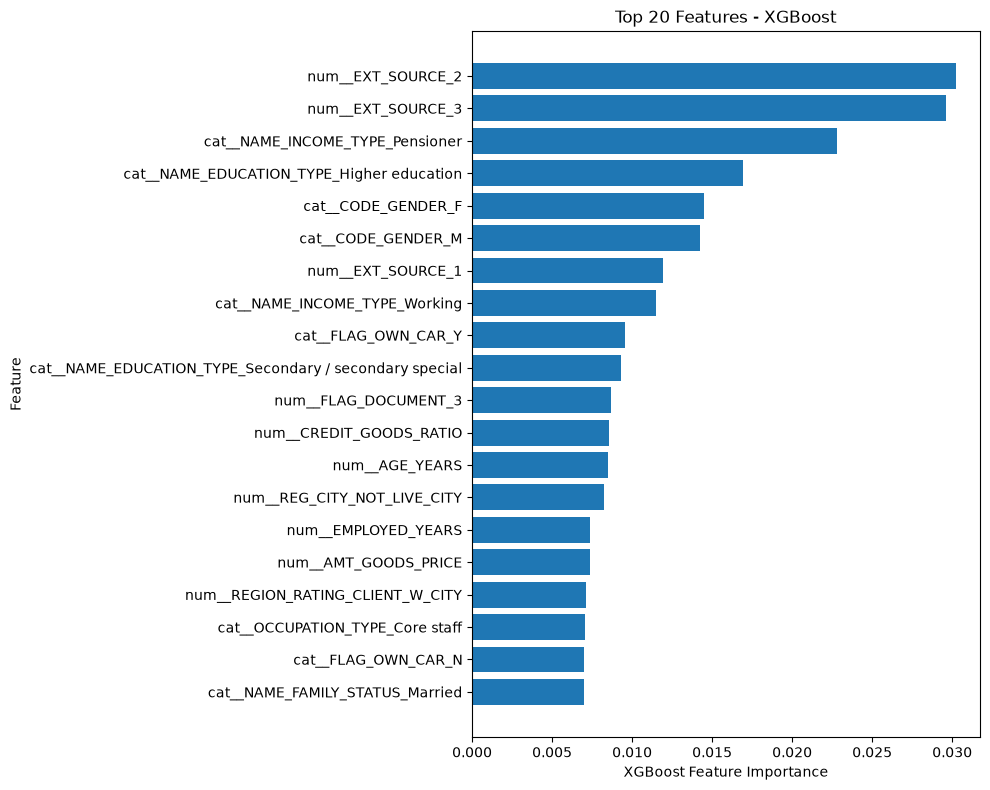

In [ ]:
import matplotlib.pyplot as plt

top_features = importance_df.head(20).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("XGBoost Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features - XGBoost")

plt.tight_layout()
plt.show()

In [ ]:
df_fe["DAYS_EMPLOYED"] = df_fe["DAYS_EMPLOYED"].replace(
    365243,
    np.nan
)

df_fe["EMPLOYED_YEARS"] = (
    -df_fe["DAYS_EMPLOYED"] / 365
)

In [ ]:
df_fe = df.copy()

# Fix special missing-value code in DAYS_EMPLOYED
df_fe["DAYS_EMPLOYED"] = df_fe["DAYS_EMPLOYED"].replace(365243, np.nan)

# Create engineered features
df_fe["CREDIT_INCOME_RATIO"] = (
    df_fe["AMT_CREDIT"] / (df_fe["AMT_INCOME_TOTAL"] + 1)
)

df_fe["ANNUITY_INCOME_RATIO"] = (
    df_fe["AMT_ANNUITY"] / (df_fe["AMT_INCOME_TOTAL"] + 1)
)

df_fe["CREDIT_GOODS_RATIO"] = (
    df_fe["AMT_CREDIT"] / (df_fe["AMT_GOODS_PRICE"] + 1)
)

df_fe["AGE_YEARS"] = -df_fe["DAYS_BIRTH"] / 365

df_fe["EMPLOYED_YEARS"] = -df_fe["DAYS_EMPLOYED"] / 365

print("Feature engineering completed.")
print("Shape:", df_fe.shape)

Feature engineering completed.
Shape: (307511, 127)


In [ ]:
df_fe[
    ["AGE_YEARS", "EMPLOYED_YEARS",
     "CREDIT_INCOME_RATIO",
     "ANNUITY_INCOME_RATIO",
     "CREDIT_GOODS_RATIO"]
].describe()

,AGE_YEARS,EMPLOYED_YEARS,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_GOODS_RATIO
count,307511.000000,252137.000000,307511.000000,307499.000000,307233.000000
mean,43.936973,6.531971,3.957537,0.180928,1.122992
std,11.956133,6.406466,2.689696,0.094573,0.124044
min,20.517808,-0.000000,0.004808,0.000224,0.150000
25%,34.008219,2.101370,2.018659,0.114781,0.999999
50%,43.150685,4.515068,3.265042,0.162832,1.118798
75%,53.923288,8.698630,5.159857,0.229064,1.197998
max,69.120548,49.073973,84.733539,1.875892,5.999867


In [ ]:
import pandas as pd
import numpy as np

df_fe = df.copy()

# Fix Home Credit special missing-value code
df_fe["DAYS_EMPLOYED"] = df_fe["DAYS_EMPLOYED"].replace(365243, np.nan)

# Feature engineering
df_fe["CREDIT_INCOME_RATIO"] = (
    df_fe["AMT_CREDIT"] / (df_fe["AMT_INCOME_TOTAL"] + 1)
)

df_fe["ANNUITY_INCOME_RATIO"] = (
    df_fe["AMT_ANNUITY"] / (df_fe["AMT_INCOME_TOTAL"] + 1)
)

df_fe["CREDIT_GOODS_RATIO"] = (
    df_fe["AMT_CREDIT"] / (df_fe["AMT_GOODS_PRICE"] + 1)
)

df_fe["AGE_YEARS"] = -df_fe["DAYS_BIRTH"] / 365

df_fe["EMPLOYED_YEARS"] = -df_fe["DAYS_EMPLOYED"] / 365

print("Feature engineering completed.")
print("Shape:", df_fe.shape)

Feature engineering completed.
Shape: (307511, 127)


In [ ]:
df_fe[
    [
        "AGE_YEARS",
        "EMPLOYED_YEARS",
        "CREDIT_INCOME_RATIO",
        "ANNUITY_INCOME_RATIO",
        "CREDIT_GOODS_RATIO"
    ]
].describe()


,AGE_YEARS,EMPLOYED_YEARS,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_GOODS_RATIO
count,307511.000000,252137.000000,307511.000000,307499.000000,307233.000000
mean,43.936973,6.531971,3.957537,0.180928,1.122992
std,11.956133,6.406466,2.689696,0.094573,0.124044
min,20.517808,-0.000000,0.004808,0.000224,0.150000
25%,34.008219,2.101370,2.018659,0.114781,0.999999
50%,43.150685,4.515068,3.265042,0.162832,1.118798
75%,53.923288,8.698630,5.159857,0.229064,1.197998
max,69.120548,49.073973,84.733539,1.875892,5.999867


In [ ]:
print("Minimum employed years:",
      df_fe["EMPLOYED_YEARS"].min())

print("Maximum employed years:",
      df_fe["EMPLOYED_YEARS"].max())

Minimum employed years: -0.0
Maximum employed years: 49.07397260273972


In [ ]:
X_fe = df_fe.drop(["TARGET", "SK_ID_CURR"], axis=1)
y_fe = df_fe["TARGET"]

print("X shape:", X_fe.shape)
print("y shape:", y_fe.shape)

X shape: (307511, 125)
y shape: (307511,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe,
    y_fe,
    test_size=0.2,
    random_state=42,
    stratify=y_fe
)

print("Training shape:", X_train_fe.shape)
print("Testing shape:", X_test_fe.shape)

Training shape: (246008, 125)
Testing shape: (61503, 125)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features_fe = X_train_fe.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features_fe = X_train_fe.select_dtypes(
    include=["object"]
).columns

numeric_transformer_fe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer_fe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_fe = ColumnTransformer([
    ("num", numeric_transformer_fe, numeric_features_fe),
    ("cat", categorical_transformer_fe, categorical_features_fe)
])

print("Numeric features:", len(numeric_features_fe))
print("Categorical features:", len(categorical_features_fe))

Numeric features: 109
Categorical features: 16


C:\Users\ASUS\AppData\Local\Temp\ipykernel_18412\1366856215.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features_fe = X_train_fe.select_dtypes(


In [ ]:
from xgboost import XGBClassifier

xgb_model = Pipeline([
    ("preprocessor", preprocessor_fe),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    ))
])

print("Training XGBoost...")
xgb_model.fit(X_train_fe, y_train_fe)

print("XGBoost training completed.")

Training XGBoost...
XGBoost training completed.


In [ ]:
xgb_probability = xgb_model.predict_proba(X_test_fe)[:, 1]

print("Probability predictions generated.")
print(xgb_probability[:10])

Probability predictions generated.
[0.05817491 0.03955933 0.28183532 0.05907033 0.06621952 0.15896879
 0.01313038 0.0075434  0.38474804 0.08876823]


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

roc_auc = roc_auc_score(y_test_fe, xgb_probability)
pr_auc = average_precision_score(y_test_fe, xgb_probability)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.762014724957329
PR-AUC: 0.25445321946738075


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

thresholds = [
    0.10, 0.15, 0.20, 0.25, 0.30,
    0.35, 0.40, 0.45, 0.50
]

for threshold in thresholds:

    threshold_pred = (
        xgb_probability >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_fe,
            threshold_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_fe,
            threshold_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_test_fe,
            threshold_pred,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,Precision,Recall,F1
0,0.10,0.191144,0.598187,0.289714
1,0.15,0.245161,0.420947,0.309859
2,0.20,0.303124,0.297080,0.300071
3,0.25,0.352699,0.206647,0.260605
4,0.30,0.399773,0.142195,0.209776
5,0.35,0.455231,0.097281,0.160305
6,0.40,0.497660,0.064250,0.113807
7,0.45,0.539510,0.039879,0.074269
8,0.50,0.598086,0.025176,0.048319


In [ ]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold = best_threshold_row["Threshold"]

print("Best threshold:", best_threshold)
print("Best F1:", best_threshold_row["F1"])

Best threshold: 0.15
Best F1: 0.30985915492957744


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

final_xgb_pred = (
    xgb_probability >= best_threshold
).astype(int)

print(
    classification_report(
        y_test_fe,
        final_xgb_pred,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test_fe, final_xgb_pred))

              precision    recall  f1-score   support

           0       0.95      0.89      0.91     56538
           1       0.25      0.42      0.31      4965

    accuracy                           0.85     61503
   macro avg       0.60      0.65      0.61     61503
weighted avg       0.89      0.85      0.87     61503

Confusion Matrix:
[[50103  6435]
 [ 2875  2090]]


In [ ]:
xgb_classifier = xgb_model.named_steps["classifier"]

feature_importances = xgb_classifier.feature_importances_

print("Number of model features:", len(feature_importances))

Number of model features: 249


In [ ]:
feature_names = xgb_model.named_steps[
    "preprocessor"
].get_feature_names_out()

print("Number of transformed features:", len(feature_names))

Number of transformed features: 249


In [ ]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(20))

,Feature,Importance
28,num__EXT_SOURCE_2,0.031413
29,num__EXT_SOURCE_3,0.030964
134,cat__NAME_EDUCATION_TYPE_Higher education,0.015302
111,cat__CODE_GENDER_F,0.013616
112,cat__CODE_GENDER_M,0.013385
137,cat__NAME_EDUCATION_TYPE_Secondary / secondary...,0.011388
27,num__EXT_SOURCE_1,0.011291
132,cat__NAME_INCOME_TYPE_Working,0.010667
79,num__FLAG_DOCUMENT_3,0.009350
115,cat__FLAG_OWN_CAR_Y,0.009331


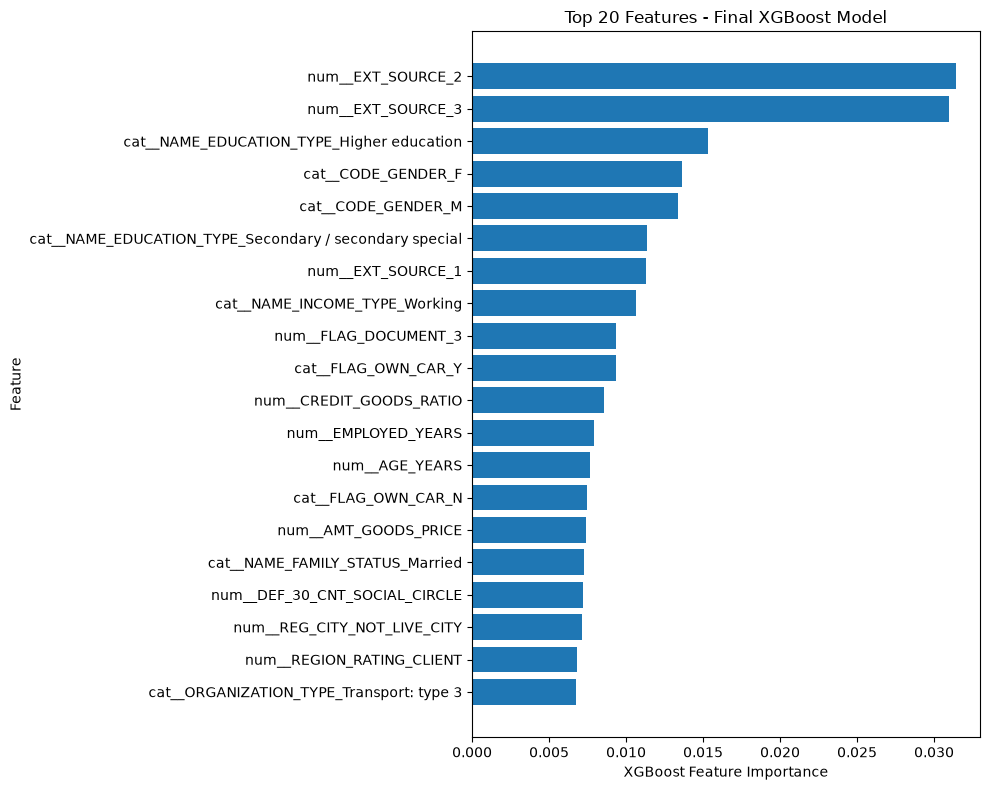

In [ ]:
import matplotlib.pyplot as plt

top_features = importance_df.head(20).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("XGBoost Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features - Final XGBoost Model")

plt.tight_layout()
plt.show()


In [ ]:
import shap

print("SHAP version:", shap.__version__)


ModuleNotFoundError: No module named 'shap'

In [ ]:
%pip install shap

   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
    --------------------------------------- 0.5/41.9 MB 2.7 MB/s eta 0:00:16
    --------------------------------------- 0.8/41.9 MB 1.7 MB/s eta 0:00:25
   - -------------------------------------- 1.0/41.9 MB 1.8 MB/s eta 0:00:23
   - -------------------------------------- 1.6/41.9 MB 1.9 MB/s eta 0:00:22
   - -------------------------------------- 1.8/41.9 MB 2.0 MB/s eta 0:00:21
   -- ------------------------------------- 2.4/41.9 MB 1.9 MB/s eta 0:00:22
   -- ------------------------------------- 2.9/41.9 MB 1.9 MB/s eta 0:00:21
   --- ------------------------------------ 3.4/41.9 MB 2.0 MB/s eta 0:00:19
   --- ------------------------------------ 3.9/41.9 MB 2.1 MB/s eta 0:00:19
   ---- ----------------------------------- 4.5/41.9 MB 2.1 MB/s eta 0:00:18
   ---- ----------------------------------- 5.0/41.9 MB 2.2 MB/s eta 0:00:17
   ----- ---------------------------------- 5.5/41.9 MB 2.2 MB/s eta 0:00:17
   ---


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [132]:
X_shap = X_test_fe.sample(
    n=2000,
    random_state=42
)

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (2000, 125)


In [133]:
preprocessor = xgb_model.named_steps["preprocessor"]
xgb_classifier = xgb_model.named_steps["classifier"]

X_shap_transformed = preprocessor.transform(X_shap)

print("Original shape:", X_shap.shape)
print("Transformed shape:", X_shap_transformed.shape)

Original shape: (2000, 125)
Transformed shape: (2000, 249)


In [134]:
feature_names = preprocessor.get_feature_names_out()

print("Number of feature names:", len(feature_names))

Number of feature names: 249


In [135]:
explainer = shap.TreeExplainer(xgb_classifier)

print("SHAP explainer created successfully.")

SHAP explainer created successfully.


In [136]:
shap_values = explainer.shap_values(X_shap_transformed)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (2000, 249)


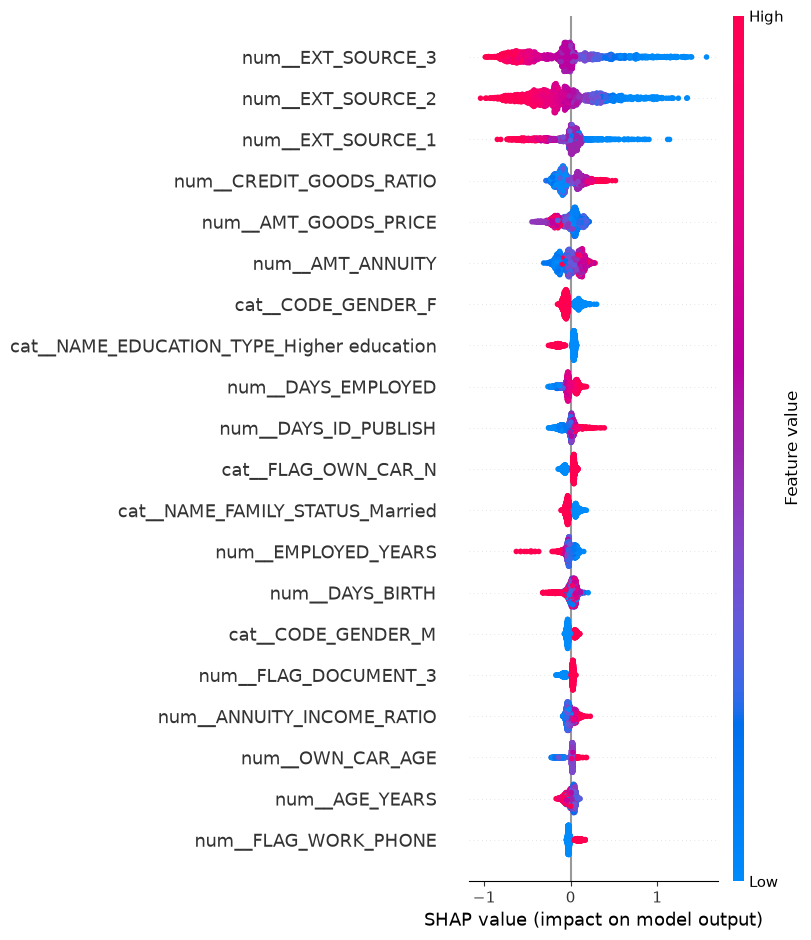

In [137]:
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    max_display=20
)

In [138]:
applicant_index = 0

X_applicant = X_test_fe.iloc[[applicant_index]]

print("Applicant shape:", X_applicant.shape)

Applicant shape: (1, 125)


In [139]:
applicant_probability = xgb_model.predict_proba(
    X_applicant
)[0, 1]

print("Predicted default probability:",
      applicant_probability)

Predicted default probability: 0.058174912


In [140]:
applicant_prediction = int(
    applicant_probability >= best_threshold
)

print("Predicted class:", applicant_prediction)

if applicant_prediction == 1:
    print("Prediction: Higher default-risk class")
else:
    print("Prediction: Lower default-risk class")

Predicted class: 0
Prediction: Lower default-risk class


In [141]:
X_applicant_transformed = preprocessor.transform(
    X_applicant
)

applicant_shap_values = explainer.shap_values(
    X_applicant_transformed
)

print(
    "SHAP values shape:",
    applicant_shap_values.shape
)

SHAP values shape: (1, 249)


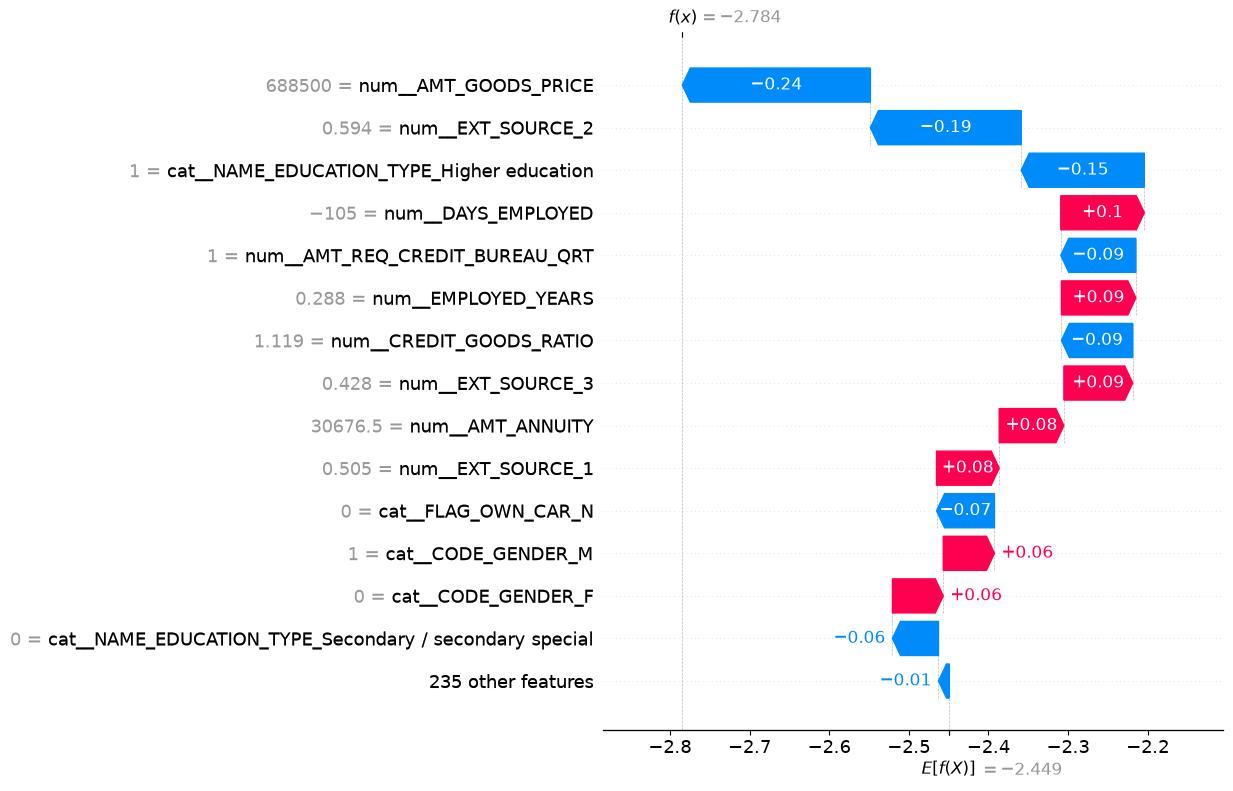

In [142]:
shap.waterfall_plot(
    shap.Explanation(
        values=applicant_shap_values[0],
        base_values=explainer.expected_value,
        data=X_applicant_transformed.toarray()[0]
            if hasattr(X_applicant_transformed, "toarray")
            else X_applicant_transformed[0],
        feature_names=feature_names
    ),
    max_display=15
)

In [143]:
import joblib
import os

model_bundle = {
    "model": xgb_model,
    "threshold": float(best_threshold)
}

print("Selected threshold:", best_threshold)

Selected threshold: 0.15


In [144]:
os.makedirs("../models", exist_ok=True)

print("Models folder ready.")

Models folder ready.


In [145]:
model_path = "../models/loan_default_model.pkl"

joblib.dump(
    model_bundle,
    model_path
)

print("Model saved successfully:")
print(model_path)

Model saved successfully:
../models/loan_default_model.pkl


In [146]:
print("File exists:", os.path.exists(model_path))

File exists: True


In [147]:
import joblib

loaded_bundle = joblib.load("../models/loan_default_model.pkl")

print("Model loaded successfully.")
print("Bundle keys:", loaded_bundle.keys())
print("Saved threshold:", loaded_bundle["threshold"])

Model loaded successfully.
Bundle keys: dict_keys(['model', 'threshold'])
Saved threshold: 0.15


In [148]:
loaded_model = loaded_bundle["model"]
loaded_threshold = loaded_bundle["threshold"]

print("Loaded model:", type(loaded_model))
print("Loaded threshold:", loaded_threshold)

Loaded model: <class 'sklearn.pipeline.Pipeline'>
Loaded threshold: 0.15


In [149]:
test_applicant = X_test_fe.iloc[[0]]

test_probability = loaded_model.predict_proba(
    test_applicant
)[0, 1]

test_prediction = int(
    test_probability >= loaded_threshold
)

print("Predicted probability:", test_probability)
print("Classification threshold:", loaded_threshold)
print("Predicted class:", test_prediction)

Predicted probability: 0.058174912
Classification threshold: 0.15
Predicted class: 0


In [150]:
original_probability = xgb_model.predict_proba(
    test_applicant
)[0, 1]

loaded_probability = loaded_model.predict_proba(
    test_applicant
)[0, 1]

print("Original model probability:", original_probability)
print("Loaded model probability:", loaded_probability)

print(
    "Match:",
    abs(original_probability - loaded_probability) < 1e-10
)

Original model probability: 0.058174912
Loaded model probability: 0.058174912
Match: True


In [151]:
import sys

sys.path.append("../src")

from predict import model, threshold

print("Model loaded:", model is not None)
print("Threshold:", threshold)

Model loaded: True
Threshold: 0.15


In [152]:
import sys

if "../src" not in sys.path:
    sys.path.append("../src")

from predict import predict_loan_risk

print("predict.py loaded successfully!")

predict.py loaded successfully!


In [153]:
import sys

if "../src" not in sys.path:
    sys.path.append("../src")

from predict import predict_loan_risk

In [154]:
test_applicant = X_test_fe.iloc[0].to_dict()

result = predict_loan_risk(test_applicant)

print(result)

{'default_probability': 0.0582, 'threshold': 0.15, 'prediction': 0, 'risk_class': 'Lower predicted default risk'}


In [155]:
test_applicant = X_test_fe.iloc[0].to_dict()

result = predict_loan_risk(test_applicant)

print(result)

{'default_probability': 0.0582, 'threshold': 0.15, 'prediction': 0, 'risk_class': 'Lower predicted default risk'}


In [2]:
import joblib
import pandas as pd

# Load the saved model
model_bundle = joblib.load("../models/loan_default_model.pkl")

xgb_model = model_bundle["model"]

# Get the trained XGBoost classifier
xgb_classifier = xgb_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = xgb_model.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance
feature_importances = xgb_classifier.feature_importances_

# Create feature-importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display top 30
display(importance_df.head(30))

,Feature,Importance
0,num__EXT_SOURCE_2,0.031413
1,num__EXT_SOURCE_3,0.030964
2,cat__NAME_EDUCATION_TYPE_Higher education,0.015302
3,cat__CODE_GENDER_F,0.013616
4,cat__CODE_GENDER_M,0.013385
5,cat__NAME_EDUCATION_TYPE_Secondary / secondary...,0.011388
6,num__EXT_SOURCE_1,0.011291
7,cat__NAME_INCOME_TYPE_Working,0.010667
8,num__FLAG_DOCUMENT_3,0.009350
9,cat__FLAG_OWN_CAR_Y,0.009331


In [4]:
import pandas as pd

# Load the original Home Credit dataset
df = pd.read_csv("../data/raw/application_train.csv")

deployment_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "NAME_EDUCATION_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_FAMILY_STATUS",
    "FLAG_OWN_CAR",
    "NAME_CONTRACT_TYPE",
    "REGION_RATING_CLIENT",
    "OCCUPATION_TYPE",
    "DEF_30_CNT_SOCIAL_CIRCLE",
    "DEF_60_CNT_SOCIAL_CIRCLE"
]

print("Number of deployment features:", len(deployment_features))

print("\nMissing features:")
print([col for col in deployment_features if col not in df.columns])

Number of deployment features: 15

Missing features:
[]


In [5]:
import pandas as pd
import numpy as np

# Target
target = "TARGET"

# Practical deployment features
deployment_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "NAME_EDUCATION_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_FAMILY_STATUS",
    "FLAG_OWN_CAR",
    "NAME_CONTRACT_TYPE",
    "REGION_RATING_CLIENT",
    "OCCUPATION_TYPE",
    "DEF_30_CNT_SOCIAL_CIRCLE",
    "DEF_60_CNT_SOCIAL_CIRCLE"
]

# Create deployment dataset
df_deployment = df[deployment_features + [target]].copy()

# Correct Home Credit special employment value
df_deployment["DAYS_EMPLOYED"] = (
    df_deployment["DAYS_EMPLOYED"]
    .replace(365243, np.nan)
)

print("Deployment dataset shape:", df_deployment.shape)

print("\nTarget distribution:")
print(df_deployment["TARGET"].value_counts())

print("\nMissing values:")
print(
    df_deployment.isnull()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

Deployment dataset shape: (307511, 16)

Target distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Missing values:
OCCUPATION_TYPE             96391
DAYS_EMPLOYED               55374
DEF_30_CNT_SOCIAL_CIRCLE     1021
DEF_60_CNT_SOCIAL_CIRCLE     1021
AMT_GOODS_PRICE               278
AMT_ANNUITY                    12
AMT_INCOME_TOTAL                0
AMT_CREDIT                      0
NAME_INCOME_TYPE                0
NAME_EDUCATION_TYPE             0
dtype: int64


In [6]:
from sklearn.model_selection import train_test_split

# Separate features and target
X_deploy = df_deployment.drop(columns=["TARGET"])
y_deploy = df_deployment["TARGET"]

# Stratified split
X_train_deploy, X_test_deploy, y_train_deploy, y_test_deploy = train_test_split(
    X_deploy,
    y_deploy,
    test_size=0.20,
    random_state=42,
    stratify=y_deploy
)

print("Training shape:", X_train_deploy.shape)
print("Testing shape:", X_test_deploy.shape)

print("\nTraining target distribution:")
print(y_train_deploy.value_counts())

print("\nTesting target distribution:")
print(y_test_deploy.value_counts())

Training shape: (246008, 15)
Testing shape: (61503, 15)

Training target distribution:
TARGET
0    226148
1     19860
Name: count, dtype: int64

Testing target distribution:
TARGET
0    56538
1     4965
Name: count, dtype: int64


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify numeric and categorical columns
numeric_features_deploy = X_train_deploy.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features_deploy = X_train_deploy.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numeric features:", numeric_features_deploy)
print("\nNumber of numeric features:", len(numeric_features_deploy))

print("\nCategorical features:", categorical_features_deploy)
print("\nNumber of categorical features:", len(categorical_features_deploy))


# Numeric preprocessing
numeric_transformer_deploy = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])


# Categorical preprocessing
categorical_transformer_deploy = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


# Complete preprocessing
preprocessor_deploy = ColumnTransformer([
    ("num", numeric_transformer_deploy, numeric_features_deploy),
    ("cat", categorical_transformer_deploy, categorical_features_deploy)
])

print("\nPreprocessing pipeline created successfully!")

Numeric features: ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'REGION_RATING_CLIENT', 'DEF_30_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE']

Number of numeric features: 9

Categorical features: ['NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'FLAG_OWN_CAR', 'NAME_CONTRACT_TYPE', 'OCCUPATION_TYPE']

Number of categorical features: 6

Preprocessing pipeline created successfully!


C:\Users\ASUS\AppData\Local\Temp\ipykernel_11604\387118634.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features_deploy = X_train_deploy.select_dtypes(


In [8]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

deployment_model = Pipeline([
    ("preprocessor", preprocessor_deploy),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=11.38710976837865,
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    ))
])

print("Starting deployment model training...")

deployment_model.fit(
    X_train_deploy,
    y_train_deploy
)

print("Deployment model trained successfully!")

Starting deployment model training...
Deployment model trained successfully!


In [9]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Predict probabilities
y_proba_deploy = deployment_model.predict_proba(X_test_deploy)[:, 1]

# Default threshold = 0.50
y_pred_deploy = (y_proba_deploy >= 0.50).astype(int)

# Metrics
roc_auc_deploy = roc_auc_score(y_test_deploy, y_proba_deploy)
pr_auc_deploy = average_precision_score(y_test_deploy, y_proba_deploy)

print("===== DEPLOYMENT MODEL EVALUATION =====")
print(f"ROC-AUC : {roc_auc_deploy:.4f}")
print(f"PR-AUC  : {pr_auc_deploy:.4f}")

print("\n===== CLASSIFICATION REPORT (Threshold = 0.50) =====")
print(classification_report(y_test_deploy, y_pred_deploy))

print("===== CONFUSION MATRIX =====")
print(confusion_matrix(y_test_deploy, y_pred_deploy))

===== DEPLOYMENT MODEL EVALUATION =====
ROC-AUC : 0.6843
PR-AUC  : 0.1696

===== CLASSIFICATION REPORT (Threshold = 0.50) =====
              precision    recall  f1-score   support

           0       0.95      0.68      0.79     56538
           1       0.14      0.58      0.22      4965

    accuracy                           0.67     61503
   macro avg       0.54      0.63      0.51     61503
weighted avg       0.88      0.67      0.75     61503

===== CONFUSION MATRIX =====
[[38615 17923]
 [ 2075  2890]]


In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

threshold_results_deploy = []

for threshold in np.arange(0.05, 0.51, 0.05):
    y_pred = (y_proba_deploy >= threshold).astype(int)

    precision = precision_score(y_test_deploy, y_pred, zero_division=0)
    recall = recall_score(y_test_deploy, y_pred, zero_division=0)
    f1 = f1_score(y_test_deploy, y_pred, zero_division=0)

    threshold_results_deploy.append({
        "threshold": round(float(threshold), 2),
        "precision": round(float(precision), 4),
        "recall": round(float(recall), 4),
        "f1": round(float(f1), 4)
    })

threshold_df_deploy = pd.DataFrame(threshold_results_deploy)

print(threshold_df_deploy)

best_row_deploy = threshold_df_deploy.loc[
    threshold_df_deploy["f1"].idxmax()
]

print("\n===== BEST THRESHOLD =====")
print(best_row_deploy)


   threshold  precision  recall      f1
0       0.05     0.0809  1.0000  0.1496
1       0.10     0.0814  0.9988  0.1505
2       0.15     0.0824  0.9934  0.1522
3       0.20     0.0847  0.9849  0.1559
4       0.25     0.0881  0.9646  0.1615
5       0.30     0.0936  0.9303  0.1700
6       0.35     0.1007  0.8683  0.1805
7       0.40     0.1110  0.7861  0.1945
8       0.45     0.1240  0.6860  0.2101
9       0.50     0.1389  0.5821  0.2242

===== BEST THRESHOLD =====
threshold    0.5000
precision    0.1389
recall       0.5821
f1           0.2242
Name: 9, dtype: float64


In [11]:
deployment_features_v2 = [
    # Financial information
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",

    # Credit history / external risk indicators
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",

    # Personal / employment information
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",

    # Loan information
    "NAME_CONTRACT_TYPE",

    # Education / employment
    "NAME_EDUCATION_TYPE",
    "NAME_INCOME_TYPE",
    "OCCUPATION_TYPE",

    # Family / assets
    "NAME_FAMILY_STATUS",
    "FLAG_OWN_CAR",

    # Previous social credit issues
    "DEF_30_CNT_SOCIAL_CIRCLE",
    "DEF_60_CNT_SOCIAL_CIRCLE",

    # Regional risk
    "REGION_RATING_CLIENT"
]

print("Number of deployment features:", len(deployment_features_v2))
print("\nDeployment features:")
for i, feature in enumerate(deployment_features_v2, start=1):
    print(f"{i}. {feature}")

Number of deployment features: 18

Deployment features:
1. AMT_INCOME_TOTAL
2. AMT_CREDIT
3. AMT_ANNUITY
4. AMT_GOODS_PRICE
5. EXT_SOURCE_1
6. EXT_SOURCE_2
7. EXT_SOURCE_3
8. DAYS_BIRTH
9. DAYS_EMPLOYED
10. NAME_CONTRACT_TYPE
11. NAME_EDUCATION_TYPE
12. NAME_INCOME_TYPE
13. OCCUPATION_TYPE
14. NAME_FAMILY_STATUS
15. FLAG_OWN_CAR
16. DEF_30_CNT_SOCIAL_CIRCLE
17. DEF_60_CNT_SOCIAL_CIRCLE
18. REGION_RATING_CLIENT


In [12]:
# Create deployment dataset using the improved 18-feature set

df_deployment_v2 = df[deployment_features_v2 + ["TARGET"]].copy()

# Home Credit uses 365243 as a special value for unknown DAYS_EMPLOYED
df_deployment_v2["DAYS_EMPLOYED"] = (
    df_deployment_v2["DAYS_EMPLOYED"].replace(365243, np.nan)
)

print("Deployment v2 dataset shape:", df_deployment_v2.shape)

print("\nTarget distribution:")
print(df_deployment_v2["TARGET"].value_counts())

print("\nMissing values:")
print(
    df_deployment_v2.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

Deployment v2 dataset shape: (307511, 19)

Target distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Missing values:
EXT_SOURCE_1                173378
OCCUPATION_TYPE              96391
EXT_SOURCE_3                 60965
DAYS_EMPLOYED                55374
DEF_30_CNT_SOCIAL_CIRCLE      1021
DEF_60_CNT_SOCIAL_CIRCLE      1021
EXT_SOURCE_2                   660
AMT_GOODS_PRICE                278
AMT_ANNUITY                     12
AMT_CREDIT                       0
AMT_INCOME_TOTAL                 0
NAME_EDUCATION_TYPE              0
NAME_CONTRACT_TYPE               0
DAYS_BIRTH                       0
NAME_INCOME_TYPE                 0
dtype: int64


In [13]:
from sklearn.model_selection import train_test_split

# Separate features and target
X_deploy_v2 = df_deployment_v2.drop(columns=["TARGET"])
y_deploy_v2 = df_deployment_v2["TARGET"]

# Stratified train/test split
X_train_deploy_v2, X_test_deploy_v2, y_train_deploy_v2, y_test_deploy_v2 = train_test_split(
    X_deploy_v2,
    y_deploy_v2,
    test_size=0.20,
    random_state=42,
    stratify=y_deploy_v2
)

print("Training data shape:", X_train_deploy_v2.shape)
print("Testing data shape :", X_test_deploy_v2.shape)

print("\nTraining target distribution:")
print(y_train_deploy_v2.value_counts())

print("\nTesting target distribution:")
print(y_test_deploy_v2.value_counts())

Training data shape: (246008, 18)
Testing data shape : (61503, 18)

Training target distribution:
TARGET
0    226148
1     19860
Name: count, dtype: int64

Testing target distribution:
TARGET
0    56538
1     4965
Name: count, dtype: int64


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify numeric and categorical features
numeric_features_deploy_v2 = X_train_deploy_v2.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features_deploy_v2 = X_train_deploy_v2.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numeric features:")
print(numeric_features_deploy_v2)
print("\nNumber of numeric features:", len(numeric_features_deploy_v2))

print("\nCategorical features:")
print(categorical_features_deploy_v2)
print("\nNumber of categorical features:", len(categorical_features_deploy_v2))

# Numeric preprocessing
numeric_transformer_deploy_v2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer_deploy_v2 = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor_deploy_v2 = ColumnTransformer([
    ("num", numeric_transformer_deploy_v2, numeric_features_deploy_v2),
    ("cat", categorical_transformer_deploy_v2, categorical_features_deploy_v2)
])

print("\nV2 preprocessing pipeline created successfully!")

Numeric features:
['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DEF_30_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE', 'REGION_RATING_CLIENT']

Number of numeric features: 12

Categorical features:
['NAME_CONTRACT_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE', 'OCCUPATION_TYPE', 'NAME_FAMILY_STATUS', 'FLAG_OWN_CAR']

Number of categorical features: 6

V2 preprocessing pipeline created successfully!


C:\Users\ASUS\AppData\Local\Temp\ipykernel_11604\3152662067.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features_deploy_v2 = X_train_deploy_v2.select_dtypes(


In [15]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

deployment_model_v2 = Pipeline([
    ("preprocessor", preprocessor_deploy_v2),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=11.38710976837865,
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    ))
])

print("Starting v2 deployment model training...")

deployment_model_v2.fit(
    X_train_deploy_v2,
    y_train_deploy_v2
)

print("V2 deployment model trained successfully!")

Starting v2 deployment model training...
V2 deployment model trained successfully!


In [16]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Predict probabilities
y_proba_deploy_v2 = deployment_model_v2.predict_proba(
    X_test_deploy_v2
)[:, 1]

# Default threshold
y_pred_deploy_v2 = (
    y_proba_deploy_v2 >= 0.50
).astype(int)

# Calculate metrics
roc_auc_deploy_v2 = roc_auc_score(
    y_test_deploy_v2,
    y_proba_deploy_v2
)

pr_auc_deploy_v2 = average_precision_score(
    y_test_deploy_v2,
    y_proba_deploy_v2
)

print("===== V2 DEPLOYMENT MODEL EVALUATION =====")
print(f"ROC-AUC : {roc_auc_deploy_v2:.4f}")
print(f"PR-AUC  : {pr_auc_deploy_v2:.4f}")

print("\n===== CLASSIFICATION REPORT (Threshold = 0.50) =====")
print(
    classification_report(
        y_test_deploy_v2,
        y_pred_deploy_v2
    )
)

print("===== CONFUSION MATRIX =====")
print(
    confusion_matrix(
        y_test_deploy_v2,
        y_pred_deploy_v2
    )
)

===== V2 DEPLOYMENT MODEL EVALUATION =====
ROC-AUC : 0.7547
PR-AUC  : 0.2442

===== CLASSIFICATION REPORT (Threshold = 0.50) =====
              precision    recall  f1-score   support

           0       0.96      0.72      0.82     56538
           1       0.17      0.66      0.27      4965

    accuracy                           0.71     61503
   macro avg       0.56      0.69      0.54     61503
weighted avg       0.90      0.71      0.78     61503

===== CONFUSION MATRIX =====
[[40519 16019]
 [ 1708  3257]]


In [17]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

threshold_results_v2 = []

for threshold in np.arange(0.05, 0.51, 0.05):
    y_pred = (y_proba_deploy_v2 >= threshold).astype(int)

    precision = precision_score(
        y_test_deploy_v2,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test_deploy_v2,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test_deploy_v2,
        y_pred,
        zero_division=0
    )

    threshold_results_v2.append({
        "threshold": round(float(threshold), 2),
        "precision": round(float(precision), 4),
        "recall": round(float(recall), 4),
        "f1": round(float(f1), 4)
    })

threshold_df_v2 = pd.DataFrame(threshold_results_v2)

print(threshold_df_v2)

best_row_v2 = threshold_df_v2.loc[
    threshold_df_v2["f1"].idxmax()
]

print("\n===== BEST V2 THRESHOLD =====")
print(best_row_v2)

   threshold  precision  recall      f1
0       0.05     0.0814  0.9996  0.1505
1       0.10     0.0842  0.9950  0.1552
2       0.15     0.0889  0.9797  0.1630
3       0.20     0.0959  0.9575  0.1743
4       0.25     0.1048  0.9289  0.1883
5       0.30     0.1151  0.8922  0.2039
6       0.35     0.1265  0.8425  0.2199
7       0.40     0.1393  0.7869  0.2367
8       0.45     0.1526  0.7241  0.2521
9       0.50     0.1690  0.6560  0.2687

===== BEST V2 THRESHOLD =====
threshold    0.5000
precision    0.1690
recall       0.6560
f1           0.2687
Name: 9, dtype: float64


In [18]:
import joblib
import os

# Deployment model bundle
deployment_bundle_v2 = {
    "model": deployment_model_v2,
    "threshold": 0.50,
    "features": deployment_features_v2
}

# Save deployment model
os.makedirs("../models", exist_ok=True)

deployment_model_path = "../models/loan_default_deployment_v2.pkl"

joblib.dump(
    deployment_bundle_v2,
    deployment_model_path
)

print("V2 deployment model saved successfully!")
print("Path:", deployment_model_path)
print("Threshold:", deployment_bundle_v2["threshold"])
print("Number of features:", len(deployment_bundle_v2["features"]))

V2 deployment model saved successfully!
Path: ../models/loan_default_deployment_v2.pkl
Threshold: 0.5
Number of features: 18


In [19]:
import joblib
import pandas as pd
import numpy as np

# Load saved deployment model
deployment_bundle = joblib.load(
    "../models/loan_default_deployment_v2.pkl"
)

deployment_model = deployment_bundle["model"]
deployment_threshold = deployment_bundle["threshold"]
deployment_features = deployment_bundle["features"]

print("===== SAVED MODEL VERIFICATION =====")
print("Model loaded successfully")
print("Threshold:", deployment_threshold)
print("Number of features:", len(deployment_features))
print("\nFeatures:")
print(deployment_features)

# Take one real applicant from the dataset
df_check = pd.read_csv("../data/raw/application_train.csv")

applicant = df_check[
    deployment_features
].iloc[0].copy()

# Replace missing values with None for display/input purposes
applicant_dict = {
    key: None if pd.isna(value) else value
    for key, value in applicant.to_dict().items()
}

# Convert to DataFrame
input_df = pd.DataFrame([applicant_dict])

# Apply the same DAYS_EMPLOYED correction used during training
input_df["DAYS_EMPLOYED"] = input_df["DAYS_EMPLOYED"].replace(
    365243, np.nan
)

# Predict
probability = deployment_model.predict_proba(input_df)[0, 1]

prediction = int(
    probability >= deployment_threshold
)

print("\n===== PREDICTION =====")
print("Default Probability:", round(float(probability), 4))
print("Prediction:", prediction)

if prediction == 1:
    print("Risk: Higher predicted default risk")
else:
    print("Risk: Lower predicted default risk")

===== SAVED MODEL VERIFICATION =====
Model loaded successfully
Threshold: 0.5
Number of features: 18

Features:
['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'NAME_CONTRACT_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE', 'OCCUPATION_TYPE', 'NAME_FAMILY_STATUS', 'FLAG_OWN_CAR', 'DEF_30_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE', 'REGION_RATING_CLIENT']

===== PREDICTION =====
Default Probability: 0.8925
Prediction: 1
Risk: Higher predicted default risk
